# A/B-тест геймификации на EdTech-платформе

На образовательной платформе для школьников добавили систему достижений за регулярное решение задач. Команда предполагает, что с ней ученики будут чаще доводить задания до конца и чаще возвращаться на платформу. Нужно проверить, так ли это, и решить, запускать фичу на всех или нет.

Тест шёл три недели, с 4 по 24 мая 2026. Пользователей случайно разделили на две группы: A — без изменений, B — с геймификацией.

Данные: `ab_test_users_groups.csv` (ученики, группа, класс) и `ab_test_events.csv` (события учеников).

Смотрю три метрики: Completion Rate, D7 и D14. События полного прохождения курса в логах нет, поэтому Completion Rate считаю как долю завершённых ДЗ от начатых.

In [163]:
import pandas as pd

users = pd.read_csv("ab_test_users_groups.csv")
events = pd.read_csv("ab_test_events.csv")

In [164]:
%pip install -q duckdb

In [165]:
import duckdb

In [166]:
users.head()

,user_id,group,signup_date,grade
0,U300000,B,2026-03-09,5
1,U300001,B,2025-09-07,9
2,U300002,B,2026-01-11,9
3,U300003,A,2025-06-07,5
4,U300004,B,2025-12-25,11


In [167]:
events.head()

,user_id,timestamp,event_type
0,U300281,2026-05-04 00:06:44,homework_completed
1,U300733,2026-05-04 00:19:56,homework_completed
2,U304499,2026-05-04 00:22:07,login
3,U304266,2026-05-04 00:23:42,homework_started
4,U304266,2026-05-04 00:23:42,homework_started


In [168]:
events.shape

(179330, 3)

In [169]:
events.info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179330 entries, 0 to 179329
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   user_id     179330 non-null  object
 1   timestamp   179330 non-null  object
 2   event_type  179330 non-null  object
dtypes: object(3)
memory usage: 4.1+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      6008 non-null   object
 1   group        6008 non-null   object
 2   signup_date  6008 non-null   object
 3   grade        6008 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 187.9+ KB


In [170]:
events["timestamp"] = pd.to_datetime(events["timestamp"])
users["signup_date"] = pd.to_datetime(users["signup_date"])

events.info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179330 entries, 0 to 179329
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     179330 non-null  object        
 1   timestamp   179330 non-null  datetime64[ns]
 2   event_type  179330 non-null  object        
dtypes: datetime64[ns](1), object(2)
memory usage: 4.1+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   user_id      6008 non-null   object        
 1   group        6008 non-null   object        
 2   signup_date  6008 non-null   datetime64[ns]
 3   grade        6008 non-null   int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 187.9+ KB


## Проверка качества данных

In [171]:
users["group"].value_counts()

,count
group,
A,3005
B,3003


In [172]:
users["grade"].value_counts()

,count
grade,
6,914
8,888
5,862
10,854
7,840
11,834
9,816


In [173]:
events["event_type"].value_counts()

,count
event_type,
login,75552
homework_started,68317
homework_completed,28995
return_visit_d7,4519
return_visit_d14,1947


In [174]:
events.duplicated().sum()

np.int64(2)

In [175]:
events[events.duplicated(keep=False)]

,user_id,timestamp,event_type
3,U304266,2026-05-04 00:23:42,homework_started
4,U304266,2026-05-04 00:23:42,homework_started
86876,U304499,2026-05-14 13:49:54,homework_started
86877,U304499,2026-05-14 13:49:54,homework_started


In [176]:
users[users["user_id"].duplicated(keep=False)]

,user_id,group,signup_date,grade
357,U300357,A,2026-03-19,9
460,U300460,B,2025-08-12,6
920,U300920,B,2025-04-09,10
1014,U301014,A,2026-03-28,10
1087,U301087,B,2025-06-27,10
1367,U301367,B,2025-09-03,8
1554,U301554,A,2025-09-25,9
5216,U305216,B,2025-07-17,9
6000,U300357,B,2026-03-19,9
6001,U300460,A,2025-08-12,6


In [177]:
users["user_id"].nunique()

6000

In [178]:
events.groupby("user_id").size().sort_values(ascending=False).head(15)

,0
user_id,
U303729,842
U304167,829
U305378,793
U302840,790
U304266,781
U300573,771
U300733,770
U302379,765
U300281,760


In [179]:
events.groupby("user_id").size().describe()

,0
count,6000.000000
mean,29.888333
std,34.001998
min,6.000000
25%,24.000000
50%,28.000000
75%,33.000000
max,842.000000


In [180]:
events[events["user_id"] == "U303729"]["event_type"].value_counts()

,count
event_type,
homework_started,308
homework_completed,285
login,248
return_visit_d14,1


In [181]:
user_events = events[events["user_id"] == "U303729"]

user_events.groupby(user_events["timestamp"].dt.date).size()

,0
timestamp,
2026-05-04,39
2026-05-05,33
2026-05-06,49
2026-05-07,51
2026-05-08,25
2026-05-09,34
2026-05-10,32
2026-05-11,48
2026-05-12,48


In [182]:
print("Начало:", events["timestamp"].min())
print("Конец:", events["timestamp"].max())

Начало: 2026-05-04 00:06:44
Конец: 2026-05-24 23:55:43


In [183]:
user_events["timestamp"].dt.hour.value_counts().sort_index()

,count
timestamp,
0,40
1,37
2,33
3,47
4,22
5,36
6,29
7,39
8,31


In [184]:
event_counts = events.groupby("user_id").size()

# порог 100: у обычных пользователей максимум 52, у этих 12 от 711
suspicious_ids = event_counts[event_counts > 100].index

print(len(suspicious_ids))
print(suspicious_ids.tolist())

12
['U300158', 'U300281', 'U300573', 'U300733', 'U302379', 'U302840', 'U303438', 'U303729', 'U304167', 'U304266', 'U304499', 'U305378']


In [185]:
users[users["user_id"].isin(suspicious_ids)]["group"].value_counts()

,count
group,
B,7
A,5


In [186]:
suspicious_events = events[events["user_id"].isin(suspicious_ids)]

pd.crosstab(
    suspicious_events["user_id"],
    suspicious_events["event_type"]
)

event_type,homework_completed,homework_started,login,return_visit_d14,return_visit_d7
user_id,,,,,
U300158,255,234,248,0,1
U300281,233,258,268,0,1
U300573,255,269,246,0,1
U300733,246,259,264,0,1
U302379,254,257,253,0,1
U302840,256,243,291,0,0
U303438,223,230,258,0,0
U303729,285,308,248,1,0
U304167,290,258,280,0,1


In [187]:
suspicious_event_count = events["user_id"].isin(suspicious_ids).sum()

print(suspicious_event_count)
print(round(suspicious_event_count / len(events) * 100, 2))

9280
5.17


In [188]:
conflict_ids = users[users["user_id"].duplicated(keep=False)]["user_id"].unique()

set(conflict_ids) & set(suspicious_ids)

set()

### Проверка качества данных
В таблице users 6008 строк, но только 6000 уникальных пользователей. У 8 пользователей указаны обе группы A и B. В events найдены 2 повторные записи.
Также обнаружены 12 пользователей с подозрительно высокой активностью: от 711 до 842 событий за три недели. Из расчетов: медиана - 28 событий, максимум среди остальных пользователей — 52.
Эти 12 аккаунтов составляют 0,2% пользователей, но на них приходится 5,17% всех событий.
Пользователи с конфликтующими группами и аномальной активностью не пересекаются.

In [189]:
events["user_id"].isin(users["user_id"]).value_counts()

,count
user_id,
True,179330


## Очистка данных и SRM

In [190]:
users_no_conflicts = users[~users["user_id"].isin(conflict_ids)].copy()

users_no_conflicts["group"].value_counts()

,count
group,
A,2997
B,2995


In [191]:
from scipy.stats import chisquare

group_counts = users_no_conflicts["group"].value_counts()

chisquare(group_counts)

Power_divergenceResult(statistic=np.float64(0.0006675567423230974), pvalue=np.float64(0.9793872546704734))

### Проверка SRM

После исключения 8 пользователей с конфликтующими группами осталось 5992 человека: 2997 в группе A и 2995 в группе B. Проверила распределение 50/50 с помощью критерия хи-квадрат. Получила p-value = 0,979.Статистически значимого отклонения от ожидаемого распределения нет. При этом проверка не исключает других проблем с качеством эксперимента.

In [192]:
events_no_conflicts = events[~events["user_id"].isin(conflict_ids)].copy()

print(events.shape)
print(events_no_conflicts.shape)

(179330, 3)
(179113, 3)


In [193]:
events_clean = events_no_conflicts.drop_duplicates().copy()

print(events_no_conflicts.shape)
print(events_clean.shape)

(179113, 3)
(179111, 3)


In [194]:
users_analysis = users_no_conflicts[~users_no_conflicts["user_id"].isin(suspicious_ids)].copy()

events_analysis = events_clean[~events_clean["user_id"].isin(suspicious_ids)].copy()

print(users_analysis.shape)
print(events_analysis.shape)

(5980, 4)
(169833, 3)


### Очистка данных

Исключила 8 пользователей с конфликтующими группами и их 217 событий и удалила 2 полных дубликата.Отдельно подготовила версию данных без 12 пользователей с аномально высокой активностью.
Итог: для основного анализа осталось 5980 пользователей и 169833 события. Исходные таблицы сохранены, чтобы при необходимости сравнить результаты до и после очистки.

## Метрики

In [195]:
user_metrics = duckdb.sql("""
    SELECT
        u.user_id,
        u."group" AS experiment_group,
        SUM(
            CASE
                WHEN e.event_type = 'homework_started' THEN 1
                ELSE 0
            END
        ) AS started_count,
        SUM(
            CASE
                WHEN e.event_type = 'homework_completed' THEN 1
                ELSE 0
            END
        ) AS completed_count
    FROM users_analysis AS u
    LEFT JOIN events_analysis AS e
        ON u.user_id = e.user_id
    GROUP BY u.user_id, u."group"
""").df()

display(user_metrics.head(10))
print("Размер таблицы:", user_metrics.shape)

,user_id,experiment_group,started_count,completed_count
0,U302555,B,12.0,5.0
1,U300559,B,7.0,5.0
2,U303948,A,5.0,2.0
3,U304583,A,9.0,3.0
4,U303395,A,13.0,6.0
5,U300355,A,10.0,2.0
6,U302785,A,13.0,5.0
7,U300101,A,14.0,8.0
8,U305481,A,9.0,3.0
9,U305652,A,8.0,2.0


Размер таблицы: (5980, 4)


In [196]:
# проверяю, нет ли деления на ноль и завершённых больше, чем начатых

duckdb.sql("""
    SELECT
        COUNT(*) AS users_total,
        SUM(CASE WHEN started_count = 0 THEN 1 ELSE 0 END) AS zero_starts,
        SUM(CASE WHEN completed_count > started_count THEN 1 ELSE 0 END) AS invalid_counts
    FROM user_metrics
""").df()

,users_total,zero_starts,invalid_counts
0,5980,0.0,0.0


In [197]:
user_completion = duckdb.sql("""
    SELECT
        user_id,
        experiment_group,
        started_count,
        completed_count,
        ROUND(
            completed_count * 100.0 / started_count,
            2
        ) AS completion_rate_pct
    FROM user_metrics
""").df()

display(user_completion.head(10))

,user_id,experiment_group,started_count,completed_count,completion_rate_pct
0,U302555,B,12.0,5.0,41.67
1,U300559,B,7.0,5.0,71.43
2,U303948,A,5.0,2.0,40.00
3,U304583,A,9.0,3.0,33.33
4,U303395,A,13.0,6.0,46.15
5,U300355,A,10.0,2.0,20.00
6,U302785,A,13.0,5.0,38.46
7,U300101,A,14.0,8.0,57.14
8,U305481,A,9.0,3.0,33.33
9,U305652,A,8.0,2.0,25.00


In [198]:
# считаю двумя способами: общий и средний по ученикам

completion_summary = duckdb.sql("""
    SELECT
        experiment_group,
        COUNT(*) AS users_total,
        SUM(started_count) AS started_total,
        SUM(completed_count) AS completed_total,
        ROUND(
            100.0 * SUM(completed_count) / SUM(started_count),
            2
        ) AS overall_completion_pct,
        ROUND(
            AVG(100.0 * completed_count / started_count),
            2
        ) AS avg_user_completion_pct
    FROM user_metrics
    GROUP BY experiment_group
    ORDER BY experiment_group
""").df()

display(completion_summary)

,experiment_group,users_total,started_total,completed_total,overall_completion_pct,avg_user_completion_pct
0,A,2992,30999.0,10712.0,34.56,34.61
1,B,2988,34109.0,15259.0,44.74,43.80


In [199]:
duckdb.sql("""
    SELECT
        experiment_group,
        ROUND(AVG(completion_rate_pct), 2) AS mean_rate,
        ROUND(MEDIAN(completion_rate_pct), 2) AS median_rate,
        ROUND(STDDEV_SAMP(completion_rate_pct), 2) AS std_rate
    FROM user_completion
    GROUP BY experiment_group
    ORDER BY experiment_group
""").df()

,experiment_group,mean_rate,median_rate,std_rate
0,A,34.61,33.33,15.61
1,B,43.80,44.44,18.09


In [200]:
# t-тест Уэлча, т.к. разброс в группах разный

from scipy.stats import ttest_ind

group_a = user_metrics[user_metrics["experiment_group"] == "A"]
group_b = user_metrics[user_metrics["experiment_group"] == "B"]

rate_a = group_a["completed_count"] / group_a["started_count"] * 100
rate_b = group_b["completed_count"] / group_b["started_count"] * 100

result = ttest_ind(rate_b, rate_a, equal_var=False)

print("Разница средних:", round(rate_b.mean() - rate_a.mean(), 2), "п.п.")
print("p-value:", result.pvalue)
print("95% ДИ:", result.confidence_interval())

Разница средних: 9.19 п.п.
p-value: 1.0068665756891044e-94
95% ДИ: ConfidenceInterval(low=np.float64(8.333509120037883), high=np.float64(10.046757941579207))


### Результаты сравнения Completion Rate

Средний Completion Rate в группе A составил 34,61%, в группе B — 43,80%. Разница 9,19 п.п. в пользу группы B.

По t-тесту Уэлча различие статистически значимо (p-value < 0,001). 95%-й доверительный интервал для разницы средних от +8,33 до +10,05 п.п.

Completion Rate рассчитывался как отношение числа завершённых ДЗ к числу начатых. В данных нет идентификаторов заданий, поэтому проверить, какие именно задания были завершены, невозможно.

В группе B средний Completion Rate статистически значимо выше. Пользователи распределены случайно, проверка SRM отклонений не выявила, поэтому разницу можно связывать с геймификацией..

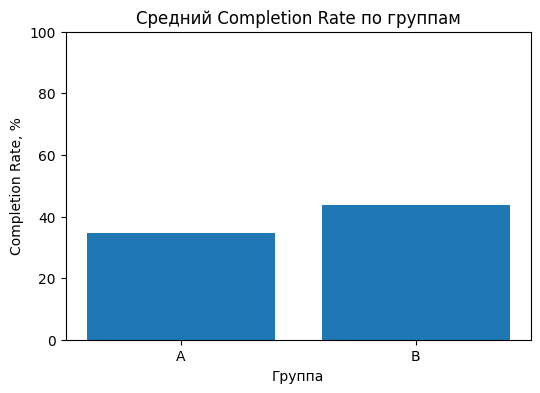

In [201]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.bar(
    completion_summary["experiment_group"],
    completion_summary["avg_user_completion_pct"]
)

plt.title("Средний Completion Rate по группам")
plt.xlabel("Группа")
plt.ylabel("Completion Rate, %")
plt.ylim(0, 100)

plt.show()

In [202]:
retention_counts = duckdb.sql("""
    SELECT
        u."group" AS experiment_group,
        COUNT(DISTINCT u.user_id) AS users_total,
        COUNT(DISTINCT CASE
            WHEN e.event_type = 'return_visit_d7' THEN e.user_id
        END) AS users_d7,
        COUNT(DISTINCT CASE
            WHEN e.event_type = 'return_visit_d14' THEN e.user_id
        END) AS users_d14
    FROM users_analysis AS u
    LEFT JOIN events_analysis AS e
        ON u.user_id = e.user_id
    GROUP BY u."group"
    ORDER BY u."group"
""").df()

display(retention_counts)

,experiment_group,users_total,users_d7,users_d14
0,A,2992,2175,862
1,B,2988,2330,1083


In [203]:
retention_summary = duckdb.sql("""
    SELECT
        experiment_group,
        users_total,
        ROUND(100.0 * users_d7 / users_total, 2) AS d7_pct,
        ROUND(100.0 * users_d14 / users_total, 2) AS d14_pct
    FROM retention_counts
    ORDER BY experiment_group
""").df()

display(retention_summary)

,experiment_group,users_total,d7_pct,d14_pct
0,A,2992,72.69,28.81
1,B,2988,77.98,36.24


In [204]:
from statsmodels.stats.proportion import proportions_ztest

groups = retention_counts.set_index("experiment_group")

successes = [groups.loc["B", "users_d7"],
             groups.loc["A", "users_d7"]]

totals = [groups.loc["B", "users_total"],
          groups.loc["A", "users_total"]]

z_stat, p_value = proportions_ztest(successes, totals)

print("z-statistic:", round(z_stat, 3))
print("p-value:", p_value)

successes_d14 = [groups.loc["B", "users_d14"],
                 groups.loc["A", "users_d14"]]

z_d14, p_d14 = proportions_ztest(successes_d14, totals)

print("D14 z-statistic:", round(z_d14, 3))
print("D14 p-value:", p_d14)
from statsmodels.stats.proportion import confint_proportions_2indep

ci_d7 = confint_proportions_2indep(
    successes[0], totals[0],
    successes[1], totals[1],
    method="wald"
)

ci_d14 = confint_proportions_2indep(
    successes_d14[0], totals[0],
    successes_d14[1], totals[1],
    method="wald"
)

print("D7: от", round(ci_d7[0] * 100, 2),
      "до", round(ci_d7[1] * 100, 2), "п.п.")

print("D14: от", round(ci_d14[0] * 100, 2),
      "до", round(ci_d14[1] * 100, 2), "п.п.")

z-statistic: 4.74
p-value: 2.1345592456812476e-06
D14 z-statistic: 6.136
D14 p-value: 8.443588554597712e-10
D7: от 3.1 до 7.47 п.п.
D14: от 5.07 до 9.8 п.п.


### Результаты сравнения D7 и D14

На D7 доля пользователей с событием возвращения составила 72,69% в группе A и 77,98% в группе B. Разница составила 5,29 п.п.

На D14 показатели составили 28,81% и 36,24% соответственно. Разница составила 7,43 п.п.

В обоих случаях различия статистически значимы (p-value < 0,001). 95%-й доверительный интервал для D7 — от +3,10 до +7,47 п.п., для D14 — от +5,07 до +9,80 п.п.

В группе B доля пользователей с событиями возвращения выше по обоим показателям. Флаги D7 и D14 взяты из логов событий, но точные правила их формирования не описаны. Поэтому эти показатели нельзя без дополнительных уточнений интерпретировать как классический Retention на 7-й и 14-й день после регистрации.

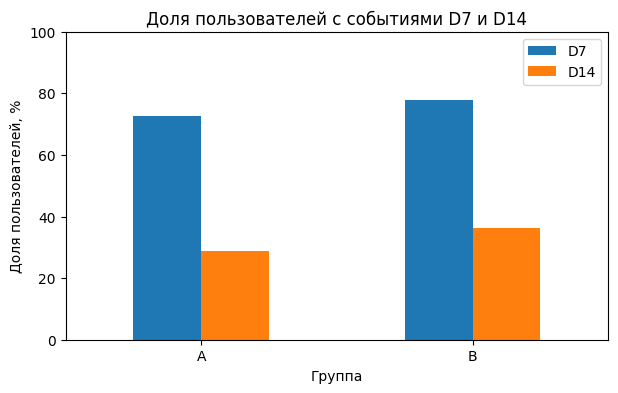

In [205]:
retention_summary.set_index("experiment_group")[["d7_pct", "d14_pct"]].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Доля пользователей с событиями D7 и D14")
plt.xlabel("Группа")
plt.ylabel("Доля пользователей, %")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(["D7", "D14"])
plt.show()

## Проверка устойчивости результатов

In [206]:
# возвращаю 12 аномальных, чтобы проверить, меняются ли выводы

users_check = users[
    ~users["user_id"].isin(conflict_ids)
].copy()

events_check = events[
    ~events["user_id"].isin(conflict_ids)
].drop_duplicates().copy()

completion_check = duckdb.sql("""
    WITH user_counts AS (
        SELECT
            u.user_id,
            u."group" AS experiment_group,
            SUM(CASE WHEN e.event_type = 'homework_started' THEN 1 ELSE 0 END) AS started,
            SUM(CASE WHEN e.event_type = 'homework_completed' THEN 1 ELSE 0 END) AS completed
        FROM users_check AS u
        LEFT JOIN events_check AS e
            ON u.user_id = e.user_id
        GROUP BY u.user_id, u."group"
    )
    SELECT
        experiment_group,
        COUNT(*) AS users_total,
        ROUND(AVG(100.0 * completed / NULLIF(started, 0)), 2) AS avg_completion_pct
    FROM user_counts
    GROUP BY experiment_group
    ORDER BY experiment_group
""").df()

display(completion_check)

,experiment_group,users_total,avg_completion_pct
0,A,2997,34.71
1,B,2995,43.92


In [207]:
retention_check = duckdb.sql("""
    SELECT
        u."group" AS experiment_group,
        COUNT(DISTINCT u.user_id) AS users_total,
        ROUND(
            100.0 * COUNT(DISTINCT CASE
                WHEN e.event_type = 'return_visit_d7' THEN e.user_id
            END) / COUNT(DISTINCT u.user_id),
            2
        ) AS d7_pct,
        ROUND(
            100.0 * COUNT(DISTINCT CASE
                WHEN e.event_type = 'return_visit_d14' THEN e.user_id
            END) / COUNT(DISTINCT u.user_id),
            2
        ) AS d14_pct
    FROM users_check AS u
    LEFT JOIN events_check AS e
        ON u.user_id = e.user_id
    GROUP BY u."group"
    ORDER BY u."group"
""").df()

display(retention_check)

,experiment_group,users_total,d7_pct,d14_pct
0,A,2997,72.71,28.76
1,B,2995,77.96,36.23


### Проверка устойчивости результатов

Пересчитала метрики с учётом 12 пользователей с аномально высокой активностью, которых исключила при очистке данных.

Средний Completion Rate практически не изменился: разница между группами составила 9,21 п.п. вместо 9,19 п.п.

Аналогичная ситуация с D7 и D14: разница между группами изменилась менее чем на 0,1 п.п.

Вывод: исключение этих пользователей не повлияло на основные выводы анализа.

## Анализ по классам

In [208]:
from scipy.stats import chi2_contingency

grade_table = duckdb.sql("""
    SELECT
        grade,
        COUNT(*) FILTER (WHERE "group" = 'A') AS group_a,
        COUNT(*) FILTER (WHERE "group" = 'B') AS group_b
    FROM users_analysis
    GROUP BY grade
    ORDER BY grade
""").df()

display(grade_table)

chi2, p_value, dof, expected = chi2_contingency(
    grade_table[["group_a", "group_b"]]
)

print("p-value:", round(p_value, 4))

,grade,group_a,group_b
0,5,446,416
1,6,446,462
2,7,402,435
3,8,454,431
4,9,430,379
5,10,409,438
6,11,405,427


p-value: 0.2372


### Сравнение групп по классам обучения

Проверила распределение учеников 5–11 классов между группами A и B. По результатам критерия хи-квадрата статистически значимых различий не обнаружено (p-value = 0,2372).

In [209]:
grade_completion = duckdb.sql("""
    SELECT
        u.grade,
        m.experiment_group,
        COUNT(*) AS users_total,
        ROUND(
            AVG(100.0 * m.completed_count / m.started_count),
            2
        ) AS avg_completion_pct
    FROM user_metrics AS m
    JOIN users_analysis AS u
        ON m.user_id = u.user_id
    GROUP BY u.grade, m.experiment_group
    ORDER BY u.grade, m.experiment_group
""").df()

display(grade_completion)

,grade,experiment_group,users_total,avg_completion_pct
0,5,A,446,35.00
1,5,B,416,55.01
2,6,A,446,33.82
3,6,B,462,53.78
4,7,A,402,35.69
5,7,B,435,51.14
6,8,A,454,34.14
7,8,B,431,42.94
8,9,A,430,34.20
9,9,B,379,43.79


In [210]:
grade_comparison = grade_completion.pivot(
    index="grade",
    columns="experiment_group",
    values="avg_completion_pct"
)

grade_comparison["difference"] = (
    grade_comparison["B"] - grade_comparison["A"]
)

display(grade_comparison)

experiment_group,A,B,difference
grade,,,
5,35.00,55.01,20.01
6,33.82,53.78,19.96
7,35.69,51.14,15.45
8,34.14,42.94,8.80
9,34.20,43.79,9.59
10,34.79,30.37,-4.42
11,34.73,29.22,-5.51


In [211]:
grade_retention = duckdb.sql("""
    SELECT
        u.grade,
        u."group" AS experiment_group,
        COUNT(DISTINCT u.user_id) AS users_total,
        ROUND(
            100.0 * COUNT(DISTINCT CASE
                WHEN e.event_type = 'return_visit_d7' THEN e.user_id
            END) / COUNT(DISTINCT u.user_id),
            2
        ) AS d7_pct,
        ROUND(
            100.0 * COUNT(DISTINCT CASE
                WHEN e.event_type = 'return_visit_d14' THEN e.user_id
            END) / COUNT(DISTINCT u.user_id),
            2
        ) AS d14_pct
    FROM users_analysis AS u
    LEFT JOIN events_analysis AS e
        ON u.user_id = e.user_id
    GROUP BY u.grade, u."group"
    ORDER BY u.grade, u."group"
""").df()

display(grade_retention)

,grade,experiment_group,users_total,d7_pct,d14_pct
0,5,A,446,72.87,28.48
1,5,B,416,82.45,43.51
2,6,A,446,75.56,30.04
3,6,B,462,86.58,45.89
4,7,A,402,70.65,26.12
5,7,B,435,84.60,43.91
6,8,A,454,73.57,28.85
7,8,B,431,77.49,34.57
8,9,A,430,71.63,29.30
9,9,B,379,78.36,34.56


In [212]:
d7_by_grade = grade_retention.pivot(
    index="grade",
    columns="experiment_group",
    values="d7_pct"
)

d14_by_grade = grade_retention.pivot(
    index="grade",
    columns="experiment_group",
    values="d14_pct"
)

grade_retention_diff = pd.DataFrame({
    "D7_diff": d7_by_grade["B"] - d7_by_grade["A"],
    "D14_diff": d14_by_grade["B"] - d14_by_grade["A"]
})

display(grade_retention_diff.round(2))

,D7_diff,D14_diff
grade,,
5,9.58,15.03
6,11.02,15.85
7,13.95,17.79
8,3.92,5.72
9,6.73,5.26
10,-1.53,-5.51
11,-6.80,-2.57


In [213]:
# 7 сравнений по классам, поэтому поправка Холма

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

grade_data = user_metrics.merge(
    users_analysis[["user_id", "grade"]],
    on="user_id",
    validate="one_to_one"
)

grade_data["completion_rate"] = (
    100.0 * grade_data["completed_count"] / grade_data["started_count"]
)

results = []

for grade in sorted(grade_data["grade"].unique()):
    a = grade_data.loc[
        (grade_data["grade"] == grade) &
        (grade_data["experiment_group"] == "A"),
        "completion_rate"
    ]

    b = grade_data.loc[
        (grade_data["grade"] == grade) &
        (grade_data["experiment_group"] == "B"),
        "completion_rate"
    ]

    p_value = ttest_ind(b, a, equal_var=False).pvalue

    results.append({
        "grade": grade,
        "difference": round(b.mean() - a.mean(), 2),
        "p_value": p_value
    })

grade_tests = pd.DataFrame(results)

grade_tests["p_adjusted"] = multipletests(
    grade_tests["p_value"],
    method="holm"
)[1]

display(grade_tests)

,grade,difference,p_value,p_adjusted
0,5,20.02,8.914761e-68,5.348856e-67
1,6,19.96,4.221106e-72,2.954774e-71
2,7,15.45,2.497765e-43,1.248882e-42
3,8,8.80,1.338566e-16,4.015697e-16
4,9,9.59,3.159107e-17,1.263643e-16
5,10,-4.42,3.146719e-05,3.146719e-05
6,11,-5.52,2.102743e-07,4.205486e-07


In [214]:
grade_retention_counts = duckdb.sql("""
    SELECT
        u.grade,
        u."group" AS experiment_group,
        COUNT(DISTINCT u.user_id) AS users_total,
        COUNT(DISTINCT CASE
            WHEN e.event_type = 'return_visit_d7'
            THEN e.user_id
        END) AS users_d7,
        COUNT(DISTINCT CASE
            WHEN e.event_type = 'return_visit_d14'
            THEN e.user_id
        END) AS users_d14
    FROM users_analysis AS u
    LEFT JOIN events_analysis AS e
        ON u.user_id = e.user_id
    GROUP BY u.grade, u."group"
    ORDER BY u.grade, u."group"
""").df()

display(grade_retention_counts)

,grade,experiment_group,users_total,users_d7,users_d14
0,5,A,446,325,127
1,5,B,416,343,181
2,6,A,446,337,134
3,6,B,462,400,212
4,7,A,402,284,105
5,7,B,435,368,191
6,8,A,454,334,131
7,8,B,431,334,149
8,9,A,430,308,126
9,9,B,379,297,131


In [215]:

from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

results = []

for grade in sorted(grade_retention_counts["grade"].unique()):
    grade_rows = grade_retention_counts[
        grade_retention_counts["grade"] == grade
    ].set_index("experiment_group")

    a = grade_rows.loc["A"]
    b = grade_rows.loc["B"]

    total = [b["users_total"], a["users_total"]]

    p_d7 = proportions_ztest(
        [b["users_d7"], a["users_d7"]], total
    )[1]

    p_d14 = proportions_ztest(
        [b["users_d14"], a["users_d14"]], total
    )[1]

    results.append({
        "grade": grade,
        "metric": "D7",
        "difference_pp": round(
            100 * (b["users_d7"] / b["users_total"] -
                   a["users_d7"] / a["users_total"]), 2
        ),
        "p_value": p_d7
    })

    results.append({
        "grade": grade,
        "metric": "D14",
        "difference_pp": round(
            100 * (b["users_d14"] / b["users_total"] -
                   a["users_d14"] / a["users_total"]), 2
        ),
        "p_value": p_d14
    })

retention_tests = pd.DataFrame(results)

d7 = retention_tests["metric"] == "D7"
d14 = retention_tests["metric"] == "D14"
# по 7 сравнений для D7 и D14, поэтому поправка Холма отдельно для каждой метрики
retention_tests.loc[d7, "p_holm"] = multipletests(
    retention_tests.loc[d7, "p_value"], method="holm"
)[1]

retention_tests.loc[d14, "p_holm"] = multipletests(
    retention_tests.loc[d14, "p_value"], method="holm"
)[1]

retention_tests["significant"] = retention_tests["p_holm"] < 0.05

display(retention_tests)


,grade,metric,difference_pp,p_value,p_holm,significant
0,5,D7,9.58,7.622551e-04,3.811275e-03,True
1,5,D14,15.03,4.168911e-06,2.084456e-05,True
2,6,D7,11.02,2.177787e-05,1.306672e-04,True
3,6,D14,15.84,8.915168e-07,5.349101e-06,True
4,7,D7,13.95,1.175334e-06,8.227335e-06,True
5,7,D14,17.79,7.532860e-08,5.273002e-07,True
6,8,D7,3.93,1.747996e-01,3.495993e-01,False
7,8,D14,5.72,6.760758e-02,2.704303e-01,False
8,9,D7,6.74,2.768911e-02,1.107564e-01,False
9,9,D14,5.26,1.086614e-01,2.704303e-01,False


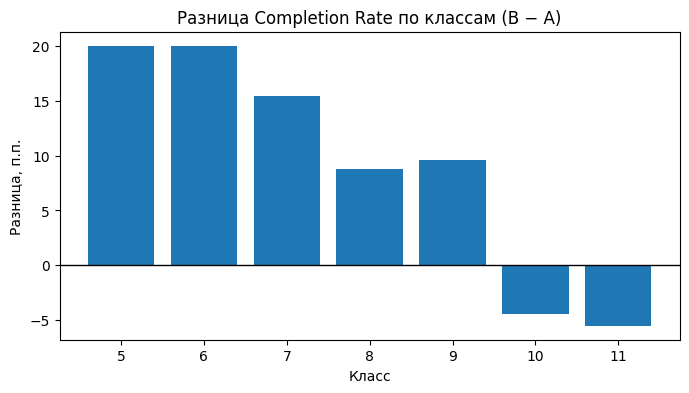

In [216]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))

plt.bar(
    grade_comparison.index,
    grade_comparison["difference"]
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Разница Completion Rate по классам (B − A)")
plt.xlabel("Класс")
plt.ylabel("Разница, п.п.")
plt.xticks(grade_comparison.index)

plt.show()

### Различия между классами

Результаты A/B-теста различаются по классам.

В 5–7 классах Completion Rate в группе B выше на 15–20 п.п., в 8–9 классах — примерно на 9 п.п. В 10–11 классах показатель, наоборот, ниже на 4–6 п.п. Все эти различия статистически значимы после поправки Холма (p-value < 0,001).

По D7 и D14 статистически значимые положительные различия обнаружены только в 5–7 классах. В 8–11 классах значимых различий по этим показателям после поправки Холма нет.

Таким образом, общий рост Completion Rate на 9,19 п.п. скрывает разные результаты по классам. Если ориентироваться только на среднее значение, можно не заметить ухудшение показателя у старшеклассников.

## Итоги A/B-теста и рекомендации

В целом группа B показала лучшие результаты:

- Completion Rate: 34,6% → 43,8% (+9,2 п.п.)
- D7: 72,7% → 78,0% (+5,3 п.п.)
- D14: 28,8% → 36,2% (+7,4 п.п.)

Все различия статистически значимы. Исключение 12 пользователей с аномальной активностью практически не повлияло на результаты.

Но по классам ситуация разная: в 5–7 классах выросли все три метрики, в 8–9 — только Completion Rate, а в 10–11 классах Completion Rate снизился на 4–6 п.п. Статистическая значимость проверялась с поправкой Холма.

**Рекомендация:** рассмотреть ограниченный запуск геймификации для 5–9 классов. Для 10–11 классов сначала стоит выяснить причины снижения Completion Rate.

Ограничения: Completion Rate рассчитан по событиям начала и завершения заданий без их идентификаторов. Правила формирования D7 и D14 неизвестны, поэтому их нельзя однозначно считать классическим Retention.